# SwiftDet-PConv-CPU — تدريب من الصفر على Kaggle (Tesla T4)

هذا الدفتر يحتوي على المشروع كاملًا: كتابة ملفات `swiftdet` → اكتشاف بيانات PASCAL VOC → فحص السلامة → التدريب من الصفر (قابل للاستئناف) → دمج QARepVGG وتصدير ONNX → تكميم INT8 QDQ → تقييم AP50 → قياس الكمون.

**قبل التشغيل**
1. من إعدادات Kaggle: `Accelerator` = **GPU T4 x1** (لا حاجة لـ x2).
2. أضف بيانات VOC كـ Input: **VOC2007 (trainval + test)** و **VOC2012 (trainval)**. المسارات لا تهم، فالدفتر يبحث عن المجلدات تلقائيًا. إن لم تجدها وكان `Internet = On` فسيحاول تنزيلها.
3. عدّل الإعدادات في الخلية الأولى (أعلام التشغيل، عدد الحقب، حد الوقت).

**الاستئناف عبر الجلسات (حد Kaggle = 12 ساعة)**
- يتوقف التدريب تلقائيًا بسلام عند `TIME_LIMIT_HOURS` ويحفظ `runs/swiftdet_voc480/last.pt`.
- احفظ النسخة بـ *Save Version → Save & Run All (Commit)*، ثم في الجلسة التالية أضف مخرجات تلك النسخة كـ Input. الدفتر يبحث عن `last.pt` ويستأنف منه.

**ملاحظات صراحة**
- لم يُشغَّل هذا الدفتر عند إنشائه؛ جرى فقط فحص الصياغة (syntax) والاستيرادات والوسائط بشكل ساكن.
- التجارب الاستئصالية المدعومة هنا هي مقارنة `simota` مقابل `atss` فقط. بقية الاستئصالات في التقرير (QARep مقابل Conv، ReLU مقابل H-Swish) تحتاج مفاتيح إضافية في الكود.
- أرقام الزمن والدقة في التقرير تقديرية. قياس الكمون في آخر الدفتر يجري على معالج Kaggle وليس على i5-3320M، فهو مؤشر نسبي فقط.

In [1]:
!kaggle kernels output youssefsalmi/fork-of-swiftdet-claude -p /kaggle/working/

Output file downloaded to /kaggle/working/outputs/swiftdet_voc480_fp32.onnx
Output file downloaded to /kaggle/working/outputs/swiftdet_voc480_int8_qdq.onnx
Output file downloaded to /kaggle/working/outputs/swiftdet_voc480_prep.onnx
Output file downloaded to /kaggle/working/runs/swiftdet_voc480/ema_ep024.pt
Output file downloaded to /kaggle/working/runs/swiftdet_voc480/ema_ep049.pt
Output file downloaded to /kaggle/working/runs/swiftdet_voc480/ema_ep074.pt
Output file downloaded to /kaggle/working/runs/swiftdet_voc480/ema_ep099.pt
Output file downloaded to /kaggle/working/runs/swiftdet_voc480/ema_ep124.pt
Output file downloaded to /kaggle/working/runs/swiftdet_voc480/ema_ep149.pt
Output file downloaded to /kaggle/working/runs/swiftdet_voc480/ema_ep174.pt
Output file downloaded to /kaggle/working/runs/swiftdet_voc480/ema_ep199.pt
Output file downloaded to /kaggle/working/runs/swiftdet_voc480/ema_ep224.pt
Output file downloaded to /kaggle/working/runs/swiftdet_voc480/ema_ep249.pt
Output f

In [2]:
import os, sys, re, glob, json, time, shutil, subprocess, importlib
from pathlib import Path

# ======================= USER SETTINGS =======================
RUN_SANITY_CHECK    = True     # overfit-one-batch check (a few minutes)
RUN_MINI_ABLATIONS  = False    # simota vs atss on VOC07 only (80 epochs each, ~1-1.5 h each)
RUN_FULL_TRAINING   = True
RUN_EXPORT_QUANTIZE = True
RUN_EVAL_ONNX       = True
RUN_CPU_BENCHMARK   = True

EPOCHS             = 300
BATCH_SIZE         = 128
NUM_WORKERS        = 4
TIME_LIMIT_HOURS   = 10        # graceful stop before Kaggle's 12h session limit
VAL_EVERY          = 20        # quick EMA validation (500 imgs) every N epochs, 0 = off
ALLOW_VOC_DOWNLOAD = True      # only used if VOC is not found under /kaggle/input (needs Internet ON)
CLEAN_DOWNLOADED_VOC_AT_END = True   # keep /kaggle/working small when the notebook is committed
MANUAL_RESUME_PATH = ""        # optional path to a last.pt; empty = auto-detect
# =============================================================

WORK = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
os.chdir(WORK)
sys.path.insert(0, str(WORK))
os.environ["PYTHONPATH"] = str(WORK) + os.pathsep + os.environ.get("PYTHONPATH", "")


def sh(cmd, check=True, cwd=None):
    """Run a shell command and stream its output live."""
    print(f"$ {cmd}", flush=True)
    env = dict(os.environ, PYTHONUNBUFFERED="1")
    proc = subprocess.Popen(cmd, shell=True, cwd=str(cwd or WORK), stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, bufsize=1, env=env)
    for line in proc.stdout:
        print(line, end="", flush=True)
    rc = proc.wait()
    if check and rc != 0:
        raise RuntimeError(f"Command failed (exit code {rc}): {cmd}")
    return rc


print("Working dir:", WORK)

Working dir: /kaggle/working


In [3]:
def pip_ensure(mapping):
    missing = []
    for mod, pip_name in mapping.items():
        try:
            importlib.import_module(mod)
        except ImportError:
            missing.append(pip_name)
    if missing:
        print("Installing:", missing)
        sh(f"{sys.executable} -m pip install -q " + " ".join(missing), check=False)


pip_ensure({"yaml": "pyyaml", "cv2": "opencv-python-headless", "psutil": "psutil",
            "onnx": "onnx", "onnxruntime": "onnxruntime", "pandas": "pandas", "matplotlib": "matplotlib"})
sh("nvidia-smi", check=False)

Installing: ['onnxruntime']
$ /usr/bin/python3 -m pip install -q onnxruntime
$ nvidia-smi
Mon Nov 23 00:33:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |       

0

In [4]:
# Package skeleton (the %%writefile cells below fill it in)
for d in ["swiftdet", "swiftdet/models", "swiftdet/losses", "swiftdet/data", "swiftdet/configs",
          "outputs", "runs"]:
    Path(d).mkdir(parents=True, exist_ok=True)
for d in ["swiftdet", "swiftdet/models", "swiftdet/losses", "swiftdet/data"]:
    (Path(d) / "__init__.py").touch()
print("Project skeleton ready.")

Project skeleton ready.


## 1) كتابة ملفات المشروع
كل خلية تحتها تكتب ملفًا واحدًا إلى `/kaggle/working/swiftdet/...` (يمكنك تعديلها قبل التشغيل).

In [5]:
%%writefile swiftdet/configs/voc_swiftdet.yaml
model:
  name: SwiftDet-PConv-CPU
  num_classes: 20
  reg_max: 7
  strides: [8, 16, 32]
  neck_channels: 64
  input_size: [480, 480]

data:
  dataset: pascal_voc_0712
  root: /kaggle/input
  train_sets: [["2007", "trainval"], ["2012", "trainval"]]
  val_set: [["2007", "test"]]
  num_workers: 4

train:
  seed: 42
  epochs: 300
  no_aug_epochs: 20
  batch_size: 64
  amp_fp16: true
  channels_last: true
  optimizer: SGD
  lr0: 0.01
  momentum: 0.937
  weight_decay: 0.0005
  warmup_epochs: 5
  ema_decay: 0.9998
  mosaic_prob: 0.8
  mixup_prob: 0.15
  assigner: simota
  grad_clip: 10.0
  val_every: 20
  val_images: 500
  loss_weights:
    vfl: 1.0
    giou: 2.0
    dfl: 0.25

deploy:
  opset: 17
  onnx_fp32: outputs/swiftdet_voc480_fp32.onnx
  onnx_int8_qdq: outputs/swiftdet_voc480_int8_qdq.onnx
  calib_images: 300
  reduce_range: true


Overwriting swiftdet/configs/voc_swiftdet.yaml


In [6]:
%%writefile swiftdet/models/blocks.py
import torch
import torch.nn as nn
import torch.nn.functional as F


def fuse_conv_bn_weights(conv_w, conv_b, bn):
    std = torch.sqrt(bn.running_var + bn.eps)
    scale = bn.weight / std
    w_fused = conv_w * scale.reshape(-1, 1, 1, 1)
    b_base = conv_b if conv_b is not None else torch.zeros_like(bn.running_mean)
    b_fused = bn.bias + (b_base - bn.running_mean) * scale
    return w_fused, b_fused


class ConvBNReLU(nn.Module):
    def __init__(self, cin, cout, k=3, s=1, p=None, act=True):
        super().__init__()
        if p is None:
            p = k // 2
        self.conv = nn.Conv2d(cin, cout, k, s, p, bias=False)
        self.bn = nn.BatchNorm2d(cout)
        self.act = nn.ReLU(inplace=True) if act else nn.Identity()
        self.deploy_mode = False

    def forward(self, x):
        if self.deploy_mode:
            return self.act(self.conv(x))
        return self.act(self.bn(self.conv(x)))

    def fuse_for_deploy(self):
        if self.deploy_mode:
            return
        w, b = fuse_conv_bn_weights(self.conv.weight, None, self.bn)
        fused = nn.Conv2d(
            self.conv.in_channels,
            self.conv.out_channels,
            self.conv.kernel_size,
            self.conv.stride,
            self.conv.padding,
            bias=True,
        )
        fused.weight.data.copy_(w)
        fused.bias.data.copy_(b)
        self.conv = fused
        delattr(self, "bn")
        self.deploy_mode = True


class QARepConv2d(nn.Module):
    """Quantization-Aware RepVGG block (Chu et al., AAAI 2024)."""
    def __init__(self, cin, cout, k=3, s=1, p=1):
        super().__init__()
        assert k == 3 and p == 1
        self.cin = cin
        self.cout = cout
        self.s = s
        self.deploy_mode = False
        self.act = nn.ReLU(inplace=True)

        self.conv3 = nn.Conv2d(cin, cout, 3, stride=s, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(cout)
        self.conv1 = nn.Conv2d(cin, cout, 1, stride=s, padding=0, bias=True)
        self.has_identity = (cin == cout and s == 1)
        self.post_bn = nn.BatchNorm2d(cout)

    def forward(self, x):
        if self.deploy_mode:
            return self.act(self.fused_conv(x))
        out = self.bn3(self.conv3(x)) + self.conv1(x)
        if self.has_identity:
            out = out + x
        return self.act(self.post_bn(out))

    def fuse_for_deploy(self):
        if self.deploy_mode:
            return
        w3, b3 = fuse_conv_bn_weights(self.conv3.weight, None, self.bn3)
        w1 = F.pad(self.conv1.weight, [1, 1, 1, 1])
        b1 = self.conv1.bias
        w_sum = w3 + w1
        b_sum = b3 + b1

        if self.has_identity:
            w_id = torch.zeros_like(w_sum)
            for i in range(self.cin):
                w_id[i, i, 1, 1] = 1.0
            w_sum = w_sum + w_id

        w_final, b_final = fuse_conv_bn_weights(w_sum, b_sum, self.post_bn)
        self.fused_conv = nn.Conv2d(self.cin, self.cout, 3, stride=self.s, padding=1, bias=True)
        self.fused_conv.weight.data.copy_(w_final)
        self.fused_conv.bias.data.copy_(b_final)

        for attr in ("conv3", "bn3", "conv1", "post_bn"):
            delattr(self, attr)
        self.deploy_mode = True


class PConvBlock(nn.Module):
    """FasterNet block: PConv(c/4) -> PW1(c->2c)+BN+ReLU -> PW2(2c->c)+BN + Skip."""
    def __init__(self, c, ratio=0.25, mlp_ratio=2.0):
        super().__init__()
        self.cp = int(c * ratio)
        self.c_rem = c - self.cp
        c_mid = int(c * mlp_ratio)

        self.pconv = nn.Conv2d(self.cp, self.cp, 3, stride=1, padding=1, bias=False)
        self.pw1 = ConvBNReLU(c, c_mid, k=1, s=1, p=0, act=True)
        self.pw2 = ConvBNReLU(c_mid, c, k=1, s=1, p=0, act=False)

    def forward(self, x):
        x1, x2 = torch.split(x, [self.cp, self.c_rem], dim=1)
        x1 = self.pconv(x1)
        out = torch.cat((x1, x2), dim=1)
        out = self.pw2(self.pw1(out))
        return x + out


class SPPFLight(nn.Module):
    def __init__(self, c, k=5):
        super().__init__()
        c_ = c // 2
        self.cv1 = ConvBNReLU(c, c_, k=1, s=1, p=0, act=True)
        self.pool = nn.MaxPool2d(kernel_size=k, stride=1, padding=k // 2)
        self.cv2 = ConvBNReLU(c_ * 4, c, k=1, s=1, p=0, act=True)

    def forward(self, x):
        x = self.cv1(x)
        y1 = self.pool(x)
        y2 = self.pool(y1)
        y3 = self.pool(y2)
        return self.cv2(torch.cat([x, y1, y2, y3], dim=1))


Overwriting swiftdet/models/blocks.py


In [7]:
%%writefile swiftdet/models/swiftdet.py
import torch
import torch.nn as nn
import torch.nn.functional as F
from .blocks import ConvBNReLU, QARepConv2d, PConvBlock, SPPFLight


class SwiftDetBackbone(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem_1 = ConvBNReLU(3, 16, k=3, s=2, p=1, act=True)
        self.stem_2 = QARepConv2d(16, 32, k=3, s=2, p=1)
        self.stage1 = nn.Sequential(PConvBlock(32, ratio=0.25, mlp_ratio=2.0))

        self.down2 = QARepConv2d(32, 64, k=3, s=2, p=1)
        self.stage2 = nn.Sequential(*[PConvBlock(64, 0.25, 2.0) for _ in range(2)])

        self.down3 = QARepConv2d(64, 128, k=3, s=2, p=1)
        self.stage3 = nn.Sequential(*[PConvBlock(128, 0.25, 2.0) for _ in range(3)])

        self.down4 = QARepConv2d(128, 256, k=3, s=2, p=1)
        self.stage4 = nn.Sequential(*[PConvBlock(256, 0.25, 2.0) for _ in range(2)])
        self.sppf = SPPFLight(256, k=5)

    def forward(self, x):
        x = self.stage1(self.stem_2(self.stem_1(x)))
        c3 = self.stage2(self.down2(x))
        c4 = self.stage3(self.down3(c3))
        c5 = self.sppf(self.stage4(self.down4(c4)))
        return c3, c4, c5


class SlimPANPConv(nn.Module):
    def __init__(self, in_channels=(64, 128, 256), cn=64):
        super().__init__()
        c3, c4, c5 = in_channels
        self.lat_p5 = ConvBNReLU(c5, cn, k=1, s=1, p=0)
        self.lat_p4 = ConvBNReLU(c4, cn, k=1, s=1, p=0)
        self.lat_p3 = ConvBNReLU(c3, cn, k=1, s=1, p=0)

        self.td_p4_red = ConvBNReLU(2 * cn, cn, k=1, s=1, p=0)
        self.td_p4 = PConvBlock(cn, ratio=0.25, mlp_ratio=2.0)

        self.td_p3_red = ConvBNReLU(2 * cn, cn, k=1, s=1, p=0)
        self.td_p3 = PConvBlock(cn, ratio=0.25, mlp_ratio=2.0)

        self.bu_p3_down = ConvBNReLU(cn, cn, k=3, s=2, p=1)
        self.bu_p4_red = ConvBNReLU(2 * cn, cn, k=1, s=1, p=0)
        self.bu_p4 = PConvBlock(cn, ratio=0.25, mlp_ratio=2.0)

        self.bu_p4_down = ConvBNReLU(cn, cn, k=3, s=2, p=1)
        self.bu_p5_red = ConvBNReLU(2 * cn, cn, k=1, s=1, p=0)
        self.bu_p5 = PConvBlock(cn, ratio=0.25, mlp_ratio=2.0)

    def forward(self, feats):
        c3, c4, c5 = feats
        l5 = self.lat_p5(c5)
        l4 = self.lat_p4(c4)
        l3 = self.lat_p3(c3)

        up5 = F.interpolate(l5, size=l4.shape[-2:], mode="nearest")
        p4_td = self.td_p4(self.td_p4_red(torch.cat([up5, l4], dim=1)))

        up4 = F.interpolate(p4_td, size=l3.shape[-2:], mode="nearest")
        p3_out = self.td_p3(self.td_p3_red(torch.cat([up4, l3], dim=1)))

        p4_out = self.bu_p4(self.bu_p4_red(torch.cat([self.bu_p3_down(p3_out), p4_td], dim=1)))
        p5_out = self.bu_p5(self.bu_p5_red(torch.cat([self.bu_p4_down(p4_out), l5], dim=1)))
        return p3_out, p4_out, p5_out


class HeadBranch(nn.Module):
    def __init__(self, cn=64, out_ch=20):
        super().__init__()
        self.cp = cn // 2
        self.pconv = nn.Conv2d(self.cp, self.cp, 3, stride=1, padding=1, bias=False)
        self.pw = ConvBNReLU(cn, cn, k=1, s=1, p=0, act=True)
        self.out_conv = nn.Conv2d(cn, out_ch, 1, stride=1, padding=0, bias=True)

    def forward(self, x):
        x1, x2 = torch.split(x, [self.cp, x.shape[1] - self.cp], dim=1)
        feat = self.pw(torch.cat((self.pconv(x1), x2), dim=1))
        return self.out_conv(feat)


class DecoupledGFLHead(nn.Module):
    def __init__(self, cn=64, num_classes=20, reg_max=7):
        super().__init__()
        self.num_classes = num_classes
        self.reg_max = reg_max
        self.cls_branches = nn.ModuleList([HeadBranch(cn, num_classes) for _ in range(3)])
        self.reg_branches = nn.ModuleList([HeadBranch(cn, 4 * (reg_max + 1)) for _ in range(3)])
        self._init_bias()

    def _init_bias(self):
        prior_prob = 0.01
        bias_val = -float(torch.log(torch.tensor((1.0 - prior_prob) / prior_prob)))
        for b in self.cls_branches:
            nn.init.constant_(b.out_conv.bias, bias_val)

    def forward(self, feats):
        outputs = []
        for idx, x in enumerate(feats):
            cls_logit = self.cls_branches[idx](x)
            reg_dist = self.reg_branches[idx](x)
            b, _, h, w = cls_logit.shape
            pred = torch.cat([cls_logit, reg_dist], dim=1)
            pred = pred.permute(0, 2, 3, 1).reshape(b, h * w, self.num_classes + 4 * (self.reg_max + 1))
            outputs.append(pred)
        return torch.cat(outputs, dim=1)


class SwiftDet(nn.Module):
    def __init__(self, num_classes=20, reg_max=7, neck_channels=64):
        super().__init__()
        self.backbone = SwiftDetBackbone()
        self.neck = SlimPANPConv((64, 128, 256), cn=neck_channels)
        self.head = DecoupledGFLHead(cn=neck_channels, num_classes=num_classes, reg_max=reg_max)

    def forward(self, x):
        return self.head(self.neck(self.backbone(x)))

    def deploy(self):
        for m in self.modules():
            if hasattr(m, "fuse_for_deploy"):
                m.fuse_for_deploy()
        return self


Overwriting swiftdet/models/swiftdet.py


In [8]:
%%writefile swiftdet/losses/gfl_simota.py
import torch
import torch.nn as nn
import torch.nn.functional as F


def make_grid_points(strides=(8, 16, 32), img_size=480, device="cpu"):
    centers, grid_strides, level_counts = [], [], []
    for s in strides:
        h = w = img_size // s
        yv, xv = torch.meshgrid(
            torch.arange(h, device=device, dtype=torch.float32),
            torch.arange(w, device=device, dtype=torch.float32),
            indexing="ij",
        )
        pts = torch.stack([(xv + 0.5) * s, (yv + 0.5) * s], dim=-1).reshape(-1, 2)
        centers.append(pts)
        grid_strides.append(torch.full((pts.shape[0], 1), s, device=device, dtype=torch.float32))
        level_counts.append(pts.shape[0])
    return torch.cat(centers, dim=0), torch.cat(grid_strides, dim=0), level_counts


def bbox_giou(boxes1, boxes2, eps=1e-7):
    x1 = torch.maximum(boxes1[:, 0], boxes2[:, 0])
    y1 = torch.maximum(boxes1[:, 1], boxes2[:, 1])
    x2 = torch.minimum(boxes1[:, 2], boxes2[:, 2])
    y2 = torch.minimum(boxes1[:, 3], boxes2[:, 3])
    inter = (x2 - x1).clamp(min=0) * (y2 - y1).clamp(min=0)
    area1 = (boxes1[:, 2] - boxes1[:, 0]).clamp(min=0) * (boxes1[:, 3] - boxes1[:, 1]).clamp(min=0)
    area2 = (boxes2[:, 2] - boxes2[:, 0]).clamp(min=0) * (boxes2[:, 3] - boxes2[:, 1]).clamp(min=0)
    union = area1 + area2 - inter + eps
    iou = inter / union
    cx1 = torch.minimum(boxes1[:, 0], boxes2[:, 0])
    cy1 = torch.minimum(boxes1[:, 1], boxes2[:, 1])
    cx2 = torch.maximum(boxes1[:, 2], boxes2[:, 2])
    cy2 = torch.maximum(boxes1[:, 3], boxes2[:, 3])
    c_area = (cx2 - cx1).clamp(min=0) * (cy2 - cy1).clamp(min=0) + eps
    return iou - (c_area - union) / c_area, iou


def pairwise_iou(boxes_a, boxes_b, eps=1e-7):
    tl = torch.maximum(boxes_a[:, None, :2], boxes_b[None, :, :2])
    br = torch.minimum(boxes_a[:, None, 2:], boxes_b[None, :, 2:])
    inter = (br - tl).clamp(min=0).prod(dim=-1)
    area_a = (boxes_a[:, 2] - boxes_a[:, 0]).clamp(min=0) * (boxes_a[:, 3] - boxes_a[:, 1]).clamp(min=0)
    area_b = (boxes_b[:, 2] - boxes_b[:, 0]).clamp(min=0) * (boxes_b[:, 3] - boxes_b[:, 1]).clamp(min=0)
    return inter / (area_a[:, None] + area_b[None, :] - inter + eps)


class SwiftDetLoss(nn.Module):
    def __init__(self, num_classes=20, reg_max=7, strides=(8, 16, 32), img_size=480,
                 vfl_w=1.0, giou_w=2.0, dfl_w=0.25, assigner="simota"):
        super().__init__()
        self.num_classes = num_classes
        self.reg_max = reg_max
        self.strides = strides
        self.img_size = img_size
        self.vfl_w = vfl_w
        self.giou_w = giou_w
        self.dfl_w = dfl_w
        self.assigner = assigner
        self.register_buffer("proj", torch.arange(reg_max + 1, dtype=torch.float32))
        self._grid_cache = {}

    def _grid(self, device):
        key = str(device)
        if key not in self._grid_cache:
            self._grid_cache[key] = make_grid_points(self.strides, self.img_size, device=device)
        return self._grid_cache[key]

    def decode_boxes(self, reg_dist, centers, grid_strides):
        b, n, _ = reg_dist.shape
        prob = F.softmax(reg_dist.reshape(b, n, 4, self.reg_max + 1).float(), dim=-1)
        ltrb = torch.matmul(prob, self.proj.to(reg_dist.device)) * grid_strides.unsqueeze(0)
        x1y1 = centers.unsqueeze(0) - ltrb[..., :2]
        x2y2 = centers.unsqueeze(0) + ltrb[..., 2:]
        return torch.cat([x1y1, x2y2], dim=-1)

    @staticmethod
    def varifocal_loss(pred_logits, target_score, alpha=0.75, gamma=2.0):
        pred_sigmoid = pred_logits.sigmoid()
        focal_weight = target_score * (target_score > 0.0).float() + \
                       alpha * (pred_sigmoid - target_score).abs().pow(gamma) * (target_score <= 0.0).float()
        return F.binary_cross_entropy_with_logits(pred_logits, target_score, reduction="none") * focal_weight

    def distribution_focal_loss(self, pred_dist, target_ltrb):
        target_ltrb = target_ltrb.clamp(0.0, self.reg_max - 0.01)
        tl = target_ltrb.long()
        tr = tl + 1
        wl = tr.float() - target_ltrb
        wr = 1.0 - wl
        flat = pred_dist.reshape(-1, self.reg_max + 1)
        loss_l = F.cross_entropy(flat, tl.reshape(-1), reduction="none").reshape(tl.shape)
        loss_r = F.cross_entropy(flat, tr.reshape(-1), reduction="none").reshape(tl.shape)
        return (loss_l * wl + loss_r * wr).mean(dim=-1)

    def _empty_assignment(self, num_anchors, device):
        return (torch.zeros((num_anchors, self.num_classes), device=device),
                torch.zeros((num_anchors,), dtype=torch.bool, device=device),
                torch.zeros((num_anchors, 4), device=device))

    @torch.no_grad()
    def simota_assign(self, cls_logits, pred_boxes, gt_boxes, gt_labels, centers, grid_strides):
        num_gt = gt_boxes.shape[0]
        num_anchors = centers.shape[0]
        if num_gt == 0:
            return self._empty_assignment(num_anchors, cls_logits.device)

        in_box = (centers[:, None, 0] > gt_boxes[None, :, 0]) & \
                 (centers[:, None, 0] < gt_boxes[None, :, 2]) & \
                 (centers[:, None, 1] > gt_boxes[None, :, 1]) & \
                 (centers[:, None, 1] < gt_boxes[None, :, 3])
        gt_centers = 0.5 * (gt_boxes[:, :2] + gt_boxes[:, 2:])
        r = 2.5 * grid_strides[:, 0:1]
        in_center = (torch.abs(centers[:, None, 0] - gt_centers[None, :, 0]) < r) & \
                    (torch.abs(centers[:, None, 1] - gt_centers[None, :, 1]) < r)
        fg_mask = (in_box | in_center).any(dim=1)
        is_in_boxes_and_center = in_box & in_center

        cand_idx = torch.where(fg_mask)[0]
        if cand_idx.numel() == 0:
            return self._empty_assignment(num_anchors, cls_logits.device)

        ious = pairwise_iou(pred_boxes[cand_idx], gt_boxes)
        iou_cost = -torch.log(ious.clamp(min=1e-8))
        cls_prob = cls_logits[cand_idx].float().sigmoid()
        gt_cls_prob = cls_prob[:, gt_labels]
        cls_cost = -torch.log(gt_cls_prob.clamp(min=1e-6))
        cost = cls_cost + 3.0 * iou_cost + 1e5 * (~is_in_boxes_and_center[cand_idx]).float()

        matching_matrix = torch.zeros_like(cost, dtype=torch.long)
        topk_ious, _ = torch.topk(ious, k=min(10, ious.shape[0]), dim=0)
        dynamic_ks = torch.clamp(topk_ious.sum(dim=0).int(), min=1)
        for gt_idx in range(num_gt):
            _, pos_idx = torch.topk(cost[:, gt_idx], k=min(int(dynamic_ks[gt_idx]), cost.shape[0]), largest=False)
            matching_matrix[pos_idx, gt_idx] = 1

        multi = matching_matrix.sum(dim=1) > 1
        if multi.any():
            min_gt = torch.argmin(cost[multi], dim=1)
            matching_matrix[multi] = 0
            matching_matrix[multi, min_gt] = 1

        pos_in_cand = matching_matrix.sum(dim=1) > 0
        pos_mask = torch.zeros((num_anchors,), dtype=torch.bool, device=cls_logits.device)
        pos_mask[cand_idx[pos_in_cand]] = True

        assigned_gt_idx = matching_matrix[pos_in_cand].argmax(dim=1)
        assigned_ious = ious[pos_in_cand, assigned_gt_idx]
        target_cls = torch.zeros((num_anchors, self.num_classes), device=cls_logits.device)
        target_cls[cand_idx[pos_in_cand], gt_labels[assigned_gt_idx]] = assigned_ious.clamp(min=0.0, max=1.0)
        target_boxes = torch.zeros((num_anchors, 4), device=cls_logits.device)
        target_boxes[cand_idx[pos_in_cand]] = gt_boxes[assigned_gt_idx]
        return target_cls, pos_mask, target_boxes

    @torch.no_grad()
    def atss_assign(self, pred_boxes, gt_boxes, gt_labels, centers, grid_strides, level_counts, topk=9):
        num_gt, num_anchors = gt_boxes.shape[0], centers.shape[0]
        if num_gt == 0:
            return self._empty_assignment(num_anchors, centers.device)

        # Pseudo-boxes of size 8*stride around grid centers for ATSS IoU statistics
        half = 4.0 * grid_strides
        pseudo_anchors = torch.cat([centers - half, centers + half], dim=-1)
        ious = pairwise_iou(pseudo_anchors, gt_boxes)
        gt_centers = 0.5 * (gt_boxes[:, :2] + gt_boxes[:, 2:])
        dists = torch.cdist(centers, gt_centers, p=2)

        cand_mask = torch.zeros((num_anchors, num_gt), dtype=torch.bool, device=centers.device)
        offset = 0
        for cnt in level_counts:
            _, idxs = torch.topk(dists[offset:offset + cnt], k=min(topk, cnt), dim=0, largest=False)
            cand_mask[offset + idxs, torch.arange(num_gt, device=centers.device)] = True
            offset += cnt

        nan_fill = torch.full_like(ious, float("nan"))
        cand_ious = torch.where(cand_mask, ious, nan_fill)
        mean_iou = torch.nanmean(cand_ious, dim=0, keepdim=True)
        std_iou = torch.sqrt(torch.nanmean((cand_ious - mean_iou) ** 2, dim=0, keepdim=True))
        thresh = mean_iou + std_iou

        in_box = (centers[:, None, 0] > gt_boxes[None, :, 0]) & (centers[:, None, 0] < gt_boxes[None, :, 2]) & \
                 (centers[:, None, 1] > gt_boxes[None, :, 1]) & (centers[:, None, 1] < gt_boxes[None, :, 3])
        is_pos = cand_mask & (ious >= thresh) & in_box
        ious_masked = torch.where(is_pos, ious, torch.full_like(ious, -1e6))
        max_ious, best_gt = ious_masked.max(dim=1)
        pos_mask = max_ious > -1e5

        target_cls = torch.zeros((num_anchors, self.num_classes), device=centers.device)
        target_boxes = torch.zeros((num_anchors, 4), device=centers.device)
        if pos_mask.any():
            pred_ious = pairwise_iou(pred_boxes[pos_mask], gt_boxes)
            assigned_gt = best_gt[pos_mask]
            rows = torch.arange(assigned_gt.numel(), device=centers.device)
            target_cls[pos_mask, gt_labels[assigned_gt]] = pred_ious[rows, assigned_gt].clamp(0.0, 1.0)
            target_boxes[pos_mask] = gt_boxes[assigned_gt]
        return target_cls, pos_mask, target_boxes

    def forward(self, preds, targets):
        """preds: (B, N, num_classes + 4*(reg_max+1)); always computed in FP32."""
        device = preds.device
        preds = preds.float()
        centers, grid_strides, level_counts = self._grid(device)
        cls_preds = preds[..., :self.num_classes]
        reg_preds = preds[..., self.num_classes:]
        pred_boxes_all = self.decode_boxes(reg_preds, centers, grid_strides)

        total_vfl = preds.new_zeros(())
        total_giou = preds.new_zeros(())
        total_dfl = preds.new_zeros(())
        total_pos = 0
        for i in range(preds.shape[0]):
            gt_boxes = targets[i]["boxes"].to(device)
            gt_labels = targets[i]["labels"].to(device)
            if self.assigner == "atss":
                t_cls, pos_mask, t_boxes = self.atss_assign(
                    pred_boxes_all[i].detach(), gt_boxes, gt_labels, centers, grid_strides, level_counts
                )
            else:
                t_cls, pos_mask, t_boxes = self.simota_assign(
                    cls_preds[i].detach(), pred_boxes_all[i].detach(), gt_boxes, gt_labels, centers, grid_strides
                )

            num_pos = int(pos_mask.sum().item())
            total_pos += max(num_pos, 1)
            total_vfl = total_vfl + self.varifocal_loss(cls_preds[i], t_cls).sum()

            if num_pos > 0:
                p_box = pred_boxes_all[i][pos_mask]
                g_box = t_boxes[pos_mask]
                giou, _ = bbox_giou(p_box, g_box)
                weights = t_cls[pos_mask].max(dim=1).values.clamp(min=0.1)
                total_giou = total_giou + ((1.0 - giou) * weights).sum()

                pos_centers = centers[pos_mask]
                pos_strides = grid_strides[pos_mask]
                t_ltrb = torch.cat([pos_centers - g_box[:, :2], g_box[:, 2:] - pos_centers], dim=-1) / pos_strides
                dfl_loss = self.distribution_focal_loss(
                    reg_preds[i][pos_mask].reshape(-1, 4, self.reg_max + 1), t_ltrb
                )
                total_dfl = total_dfl + (dfl_loss * weights).sum()

        norm = max(total_pos, 1)
        loss = (self.vfl_w * total_vfl + self.giou_w * total_giou + self.dfl_w * total_dfl) / norm
        return loss, {
            "vfl": (total_vfl / norm).detach(),
            "giou": (total_giou / norm).detach(),
            "dfl": (total_dfl / norm).detach(),
        }


Overwriting swiftdet/losses/gfl_simota.py


In [9]:
%%writefile swiftdet/data/voc_dataset.py
import os
import random
import re
import xml.etree.ElementTree as ET

import cv2
import numpy as np
import torch
from torch.utils.data import Dataset

cv2.setNumThreads(0)

VOC_CLASSES = (
    "aeroplane", "bicycle", "bird", "boat", "bottle", "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person", "pottedplant", "sheep", "sofa", "train", "tvmonitor"
)

_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def find_voc_dirs(root):
    """Find every VOC folder (has Annotations + JPEGImages + ImageSets) under one or more roots.

    `root` may contain several roots separated by os.pathsep.
    """
    found = []
    for r in str(root).split(os.pathsep):
        if not r or not os.path.isdir(r):
            continue
        for dirpath, dirnames, _ in os.walk(r, followlinks=True):
            if "Annotations" in dirnames and "JPEGImages" in dirnames and "ImageSets" in dirnames:
                found.append(dirpath)
                dirnames[:] = []  # do not descend into a VOC folder
    return found


def detect_year(voc_dir):
    base = os.path.basename(os.path.normpath(voc_dir))
    for y in ("2007", "2012"):
        if y in base:
            return y
    main = os.path.join(voc_dir, "ImageSets", "Main")
    for split in ("trainval", "train", "val", "test"):
        p = os.path.join(main, f"{split}.txt")
        if os.path.isfile(p):
            with open(p, "r") as f:
                first = f.readline().strip()
            if first:
                return "2007" if re.fullmatch(r"\d{6}", first) else "2012"
    return None


def resolve_sets(root, sets):
    dirs = [(d, detect_year(d)) for d in find_voc_dirs(root)]
    resolved = []
    for year, split in sets:
        hit = None
        for d, y in dirs:
            if y == year and os.path.isfile(os.path.join(d, "ImageSets", "Main", f"{split}.txt")):
                hit = d
                break
        if hit is None:
            raise FileNotFoundError(f"VOC{year} '{split}' not found under: {root}")
        resolved.append((hit, split))
    return resolved


class VOCDataset(Dataset):
    def __init__(self, root, sets=(("2007", "trainval"), ("2012", "trainval")),
                 img_size=480, train=True, mosaic_prob=0.8, mixup_prob=0.15):
        self.root = root
        self.img_size = img_size
        self.train = train
        self.mosaic_prob = mosaic_prob
        self.mixup_prob = mixup_prob
        self.cls_map = {c: i for i, c in enumerate(VOC_CLASSES)}
        self.samples = []

        for voc_dir, split in resolve_sets(root, sets):
            txt_path = os.path.join(voc_dir, "ImageSets", "Main", f"{split}.txt")
            with open(txt_path, "r") as f:
                ids = [line.strip() for line in f if line.strip()]
            for img_id in ids:
                self.samples.append((voc_dir, img_id))

    def __len__(self):
        return len(self.samples)

    def _load_raw(self, idx):
        voc_dir, img_id = self.samples[idx]
        img_path = os.path.join(voc_dir, "JPEGImages", f"{img_id}.jpg")
        img = cv2.imread(img_path)
        if img is None:
            raise RuntimeError(f"Cannot read image: {img_path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        tree = ET.parse(os.path.join(voc_dir, "Annotations", f"{img_id}.xml"))
        boxes, labels = [], []
        for obj in tree.findall("object"):
            if int(obj.findtext("difficult", "0")) == 1 and self.train:
                continue
            name = obj.findtext("name")
            if name not in self.cls_map:
                continue
            bb = obj.find("bndbox")
            x1, y1 = float(bb.findtext("xmin")) - 1, float(bb.findtext("ymin")) - 1
            x2, y2 = float(bb.findtext("xmax")) - 1, float(bb.findtext("ymax")) - 1
            if x2 > x1 + 1 and y2 > y1 + 1:
                boxes.append([x1, y1, x2, y2])
                labels.append(self.cls_map[name])
        boxes = np.array(boxes, dtype=np.float32) if boxes else np.zeros((0, 4), dtype=np.float32)
        labels = np.array(labels, dtype=np.int64) if labels else np.zeros((0,), dtype=np.int64)
        return img, boxes, labels

    def _resize_letterbox(self, img, boxes, size):
        h, w = img.shape[:2]
        r = min(size / h, size / w)
        nh, nw = int(round(h * r)), int(round(w * r))
        resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
        canvas = np.full((size, size, 3), 114, dtype=np.uint8)
        dy, dx = (size - nh) // 2, (size - nw) // 2
        canvas[dy:dy + nh, dx:dx + nw] = resized
        if len(boxes):
            boxes = boxes.copy()
            boxes[:, [0, 2]] = boxes[:, [0, 2]] * r + dx
            boxes[:, [1, 3]] = boxes[:, [1, 3]] * r + dy
        return canvas, boxes

    def _load_mosaic(self, idx):
        s = self.img_size
        xc, yc = random.randint(s // 2, 3 * s // 2), random.randint(s // 2, 3 * s // 2)
        canvas = np.full((2 * s, 2 * s, 3), 114, dtype=np.uint8)
        indices = [idx] + [random.randint(0, len(self.samples) - 1) for _ in range(3)]
        all_boxes, all_labels = [], []

        for i, qidx in enumerate(indices):
            img, boxes, labels = self._load_raw(qidx)
            h, w = img.shape[:2]
            scale = s / max(h, w) * random.uniform(0.7, 1.2)
            nh, nw = max(int(h * scale), 2), max(int(w * scale), 2)
            img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
            if i == 0:
                x1a, y1a, x2a, y2a = max(xc - nw, 0), max(yc - nh, 0), xc, yc
                x1b, y1b, x2b, y2b = nw - (x2a - x1a), nh - (y2a - y1a), nw, nh
            elif i == 1:
                x1a, y1a, x2a, y2a = xc, max(yc - nh, 0), min(xc + nw, 2 * s), yc
                x1b, y1b, x2b, y2b = 0, nh - (y2a - y1a), x2a - x1a, nh
            elif i == 2:
                x1a, y1a, x2a, y2a = max(xc - nw, 0), yc, xc, min(yc + nh, 2 * s)
                x1b, y1b, x2b, y2b = nw - (x2a - x1a), 0, nw, y2a - y1a
            else:
                x1a, y1a, x2a, y2a = xc, yc, min(xc + nw, 2 * s), min(yc + nh, 2 * s)
                x1b, y1b, x2b, y2b = 0, 0, x2a - x1a, y2a - y1a

            canvas[y1a:y2a, x1a:x2a] = img[y1b:y2b, x1b:x2b]
            if len(boxes):
                b = boxes.copy() * scale
                b[:, [0, 2]] += x1a - x1b
                b[:, [1, 3]] += y1a - y1b
                # keep only the part of each box that lies inside the pasted tile
                b[:, [0, 2]] = b[:, [0, 2]].clip(x1a, x2a)
                b[:, [1, 3]] = b[:, [1, 3]].clip(y1a, y2a)
                keep = ((b[:, 2] - b[:, 0]) > 2) & ((b[:, 3] - b[:, 1]) > 2)
                if keep.any():
                    all_boxes.append(b[keep])
                    all_labels.append(labels[keep])

        boxes = np.concatenate(all_boxes, axis=0) if all_boxes else np.zeros((0, 4), dtype=np.float32)
        labels = np.concatenate(all_labels, axis=0) if all_labels else np.zeros((0,), dtype=np.int64)
        x0, y0 = random.randint(0, s), random.randint(0, s)
        crop = np.ascontiguousarray(canvas[y0:y0 + s, x0:x0 + s])
        if len(boxes):
            boxes[:, [0, 2]] = np.clip(boxes[:, [0, 2]] - x0, 0, s)
            boxes[:, [1, 3]] = np.clip(boxes[:, [1, 3]] - y0, 0, s)
            keep = (boxes[:, 2] - boxes[:, 0] > 4) & (boxes[:, 3] - boxes[:, 1] > 4)
            boxes, labels = boxes[keep], labels[keep]
        return crop, boxes.astype(np.float32), labels

    def __getitem__(self, idx):
        if self.train and random.random() < self.mosaic_prob:
            img, boxes, labels = self._load_mosaic(idx)
            if random.random() < self.mixup_prob:
                img2, boxes2, labels2 = self._load_mosaic(random.randint(0, len(self.samples) - 1))
                lam = float(np.random.beta(8.0, 8.0))
                img = (img.astype(np.float32) * lam + img2.astype(np.float32) * (1 - lam)).astype(np.uint8)
                boxes = np.concatenate([boxes, boxes2], axis=0)
                labels = np.concatenate([labels, labels2], axis=0)
        else:
            img, boxes, labels = self._load_raw(idx)
            img, boxes = self._resize_letterbox(img, boxes, self.img_size)

        if self.train and random.random() < 0.5:
            img = np.ascontiguousarray(img[:, ::-1, :])
            if len(boxes):
                boxes = boxes.copy()
                boxes[:, [0, 2]] = self.img_size - boxes[:, [2, 0]]

        tensor = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float() / 255.0
        tensor = (tensor - _MEAN) / _STD
        return tensor, {
            "boxes": torch.from_numpy(np.ascontiguousarray(boxes, dtype=np.float32)),
            "labels": torch.from_numpy(np.ascontiguousarray(labels, dtype=np.int64)),
        }


def collate_fn(batch):
    imgs = torch.stack([b[0] for b in batch], dim=0)
    targets = [b[1] for b in batch]
    return imgs, targets


Overwriting swiftdet/data/voc_dataset.py


In [10]:
%%writefile swiftdet/eval_voc.py
import argparse

import numpy as np

from swiftdet.data.voc_dataset import VOCDataset, VOC_CLASSES


def decode_and_nms(raw_output, img_size=480, strides=(8, 16, 32), num_classes=20,
                   reg_max=7, conf_thresh=0.05, iou_thresh=0.5, max_per_class=300):
    pred = raw_output[0]
    cls_scores = 1.0 / (1.0 + np.exp(-np.clip(pred[:, :num_classes], -40, 40)))
    reg = pred[:, num_classes:].reshape(-1, 4, reg_max + 1)
    reg_exp = np.exp(reg - np.max(reg, axis=-1, keepdims=True))
    reg_prob = reg_exp / np.sum(reg_exp, axis=-1, keepdims=True)
    ltrb = np.sum(reg_prob * np.arange(reg_max + 1, dtype=np.float32), axis=-1)

    centers, step_arr = [], []
    for s in strides:
        g = img_size // s
        yv, xv = np.meshgrid(np.arange(g), np.arange(g), indexing="ij")
        pts = np.stack([(xv + 0.5) * s, (yv + 0.5) * s], axis=-1).reshape(-1, 2)
        centers.append(pts)
        step_arr.append(np.full((pts.shape[0], 1), s, dtype=np.float32))
    centers = np.concatenate(centers, axis=0)
    ltrb = ltrb * np.concatenate(step_arr, axis=0)
    boxes = np.concatenate([centers - ltrb[:, :2], centers + ltrb[:, 2:]], axis=-1)
    boxes = np.clip(boxes, 0, img_size)

    out_boxes, out_scores, out_cls = [], [], []
    for c in range(num_classes):
        scores = cls_scores[:, c]
        mask = scores >= conf_thresh
        if not np.any(mask):
            continue
        cb, cs = boxes[mask], scores[mask]
        if cs.size > max_per_class:
            top = np.argpartition(-cs, max_per_class)[:max_per_class]
            cb, cs = cb[top], cs[top]
        order = np.argsort(-cs)
        while order.size > 0:
            i = order[0]
            out_boxes.append(cb[i])
            out_scores.append(cs[i])
            out_cls.append(c)
            if order.size == 1:
                break
            xx1 = np.maximum(cb[i, 0], cb[order[1:], 0])
            yy1 = np.maximum(cb[i, 1], cb[order[1:], 1])
            xx2 = np.minimum(cb[i, 2], cb[order[1:], 2])
            yy2 = np.minimum(cb[i, 3], cb[order[1:], 3])
            inter = np.maximum(0.0, xx2 - xx1) * np.maximum(0.0, yy2 - yy1)
            area_i = (cb[i, 2] - cb[i, 0]) * (cb[i, 3] - cb[i, 1])
            area_o = (cb[order[1:], 2] - cb[order[1:], 0]) * (cb[order[1:], 3] - cb[order[1:], 1])
            iou = inter / np.maximum(area_i + area_o - inter, 1e-6)
            order = order[1:][iou <= iou_thresh]

    if not out_boxes:
        return np.zeros((0, 4)), np.zeros((0,)), np.zeros((0,), dtype=np.int64)
    return np.array(out_boxes), np.array(out_scores), np.array(out_cls, dtype=np.int64)


def compute_ap(rec, prec):
    mrec = np.concatenate(([0.0], rec, [1.0]))
    mpre = np.concatenate(([0.0], prec, [0.0]))
    for i in range(mpre.size - 1, 0, -1):
        mpre[i - 1] = np.maximum(mpre[i - 1], mpre[i])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))


def evaluate_fn(predict_fn, voc_root, img_size=480, max_images=0, conf_thresh=0.05, verbose=True):
    """Generic VOC07-test evaluation.

    predict_fn: callable taking a float32 numpy array (1,3,H,W) and returning a numpy array (1,N,52).
    Returns (AP50, mAP50-95) as fractions in [0, 1].
    """
    ds = VOCDataset(voc_root, sets=[("2007", "test")], img_size=img_size, train=False)
    n_total = len(ds)
    if max_images and max_images < n_total:
        indices = np.linspace(0, n_total - 1, max_images).astype(int).tolist()
    else:
        indices = list(range(n_total))

    n_cls = len(VOC_CLASSES)
    preds_by_cls = {c: [] for c in range(n_cls)}
    gts_by_cls = {c: {} for c in range(n_cls)}

    for k, idx in enumerate(indices):
        tensor, tgt = ds[idx]
        out = predict_fn(tensor.unsqueeze(0).numpy())
        pb, ps, pc = decode_and_nms(out, img_size=img_size, conf_thresh=conf_thresh)
        for b, s, c in zip(pb, ps, pc):
            preds_by_cls[int(c)].append((k, float(s), b))
        gb, gl = tgt["boxes"].numpy(), tgt["labels"].numpy()
        for b, c in zip(gb, gl):
            gts_by_cls[int(c)].setdefault(k, []).append(b)
        if verbose and (k + 1) % 500 == 0:
            print(f"  evaluated {k + 1}/{len(indices)} images", flush=True)

    iou_thresholds = np.linspace(0.5, 0.95, 10)
    aps_per_thresh = []
    for thr in iou_thresholds:
        cls_aps = []
        for c in range(n_cls):
            npos = sum(len(v) for v in gts_by_cls[c].values())
            if npos == 0:
                continue
            used = {key: np.zeros(len(v), dtype=bool) for key, v in gts_by_cls[c].items()}
            c_preds = sorted(preds_by_cls[c], key=lambda item: -item[1])
            tp, fp = np.zeros(len(c_preds)), np.zeros(len(c_preds))
            for j, (img_idx, _, box) in enumerate(c_preds):
                gt_list = gts_by_cls[c].get(img_idx, [])
                if not gt_list:
                    fp[j] = 1.0
                    continue
                gt_arr = np.array(gt_list)
                ix1 = np.maximum(gt_arr[:, 0], box[0])
                iy1 = np.maximum(gt_arr[:, 1], box[1])
                ix2 = np.minimum(gt_arr[:, 2], box[2])
                iy2 = np.minimum(gt_arr[:, 3], box[3])
                inter = np.maximum(0.0, ix2 - ix1) * np.maximum(0.0, iy2 - iy1)
                uni = (box[2] - box[0]) * (box[3] - box[1]) + \
                      (gt_arr[:, 2] - gt_arr[:, 0]) * (gt_arr[:, 3] - gt_arr[:, 1]) - inter
                ious = inter / np.maximum(uni, 1e-6)
                jmax = int(np.argmax(ious))
                if ious[jmax] >= thr and not used[img_idx][jmax]:
                    tp[j] = 1.0
                    used[img_idx][jmax] = True
                else:
                    fp[j] = 1.0
            fp_cum, tp_cum = np.cumsum(fp), np.cumsum(tp)
            rec = tp_cum / max(npos, 1)
            prec = tp_cum / np.maximum(tp_cum + fp_cum, 1e-6)
            cls_aps.append(compute_ap(rec, prec))
        aps_per_thresh.append(float(np.mean(cls_aps)) if cls_aps else 0.0)

    return aps_per_thresh[0], float(np.mean(aps_per_thresh))


def evaluate_onnx(onnx_path, voc_root, img_size=480, max_images=0):
    import onnxruntime as ort

    sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])

    def predict(x):
        return sess.run(None, {"images": x})[0]

    ap50, map_all = evaluate_fn(predict, voc_root, img_size=img_size, max_images=max_images)
    print(f"ONNX: {onnx_path} | AP50 = {ap50 * 100:.2f}% | mAP50-95 = {map_all * 100:.2f}%")
    return ap50, map_all


if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--onnx", type=str, required=True)
    p.add_argument("--voc-root", type=str, default="/kaggle/input")
    p.add_argument("--img-size", type=int, default=480)
    p.add_argument("--max-images", type=int, default=0)
    a = p.parse_args()
    evaluate_onnx(a.onnx, a.voc_root, a.img_size, a.max_images)


Overwriting swiftdet/eval_voc.py


In [11]:
%%writefile swiftdet/train.py
import argparse
import copy
import csv
import math
import os
import random
import time

import numpy as np
import torch
import yaml
from torch.utils.data import DataLoader

from swiftdet.data.voc_dataset import VOCDataset, collate_fn
from swiftdet.losses.gfl_simota import SwiftDetLoss
from swiftdet.models.swiftdet import SwiftDet


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


class ModelEMA:
    def __init__(self, model, decay=0.9998):
        self.ema = copy.deepcopy(model).eval()
        for p in self.ema.parameters():
            p.requires_grad_(False)
        self.decay = decay
        self.updates = 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = self.decay * (1.0 - math.exp(-self.updates / 2000.0))
        msd = model.state_dict()
        for k, v in self.ema.state_dict().items():
            if v.dtype.is_floating_point:
                v.copy_(v * d + msd[k].detach().to(v.device) * (1.0 - d))


def build_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def lr_at(epoch, tcfg, total_epochs):
    lr0, warm = tcfg["lr0"], tcfg["warmup_epochs"]
    if epoch < warm:
        return lr0 * float(epoch + 1) / warm
    progress = (epoch - warm) / max(total_epochs - warm, 1)
    return lr0 * (0.01 + 0.99 * 0.5 * (1.0 + math.cos(math.pi * progress)))


def atomic_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


@torch.no_grad()
def run_validation(ema_model, voc_root, img_size, device, max_images):
    from swiftdet.eval_voc import evaluate_fn

    ema_model.eval()

    def predict(x):
        t = torch.from_numpy(x).to(device)
        return ema_model(t).float().cpu().numpy()

    return evaluate_fn(predict, voc_root, img_size=img_size, max_images=max_images, verbose=False)


def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument("--cfg", type=str, default="swiftdet/configs/voc_swiftdet.yaml")
    p.add_argument("--data-root", type=str, default="")
    p.add_argument("--resume", type=str, default="")
    p.add_argument("--save-dir", type=str, default="runs/swiftdet_voc480")
    p.add_argument("--epochs", type=int, default=0)
    p.add_argument("--batch-size", type=int, default=0)
    p.add_argument("--workers", type=int, default=-1)
    p.add_argument("--assigner", type=str, default="")
    p.add_argument("--subset-voc07", action="store_true")
    p.add_argument("--overfit-one-batch", action="store_true")
    p.add_argument("--val-every", type=int, default=-1)
    p.add_argument("--time-limit-hours", type=float, default=0.0)
    return p.parse_args()


def main():
    args = parse_args()
    with open(args.cfg) as f:
        cfg = yaml.safe_load(f)
    tcfg = cfg["train"]
    os.makedirs(args.save_dir, exist_ok=True)
    set_seed(tcfg["seed"])

    use_cuda = torch.cuda.is_available()
    device = torch.device("cuda" if use_cuda else "cpu")
    if use_cuda:
        torch.backends.cudnn.benchmark = True
    amp_on = bool(tcfg["amp_fp16"]) and use_cuda
    use_cl = bool(tcfg["channels_last"]) and use_cuda
    img_size = cfg["model"]["input_size"][0]
    data_root = args.data_root or cfg["data"]["root"]
    batch_size = args.batch_size if args.batch_size > 0 else tcfg["batch_size"]
    workers = args.workers if args.workers >= 0 else cfg["data"]["num_workers"]
    val_every = args.val_every if args.val_every >= 0 else tcfg.get("val_every", 0)
    val_images = tcfg.get("val_images", 500)
    train_sets = [["2007", "trainval"]] if args.subset_voc07 else cfg["data"]["train_sets"]
    assigner = args.assigner or tcfg.get("assigner", "simota")
    total_epochs = args.epochs if args.epochs > 0 else tcfg["epochs"]

    print(f"[Setup] device={device} amp={amp_on} channels_last={use_cl} batch={batch_size} "
          f"workers={workers} assigner={assigner} epochs={total_epochs}", flush=True)

    train_ds = VOCDataset(
        data_root, sets=train_sets, img_size=img_size, train=True,
        mosaic_prob=tcfg["mosaic_prob"], mixup_prob=tcfg["mixup_prob"],
    )
    print(f"[Data] train images = {len(train_ds)}", flush=True)
    loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True, num_workers=workers,
        pin_memory=use_cuda, persistent_workers=False, collate_fn=collate_fn, drop_last=True,
    )

    model = SwiftDet(
        num_classes=cfg["model"]["num_classes"],
        reg_max=cfg["model"]["reg_max"],
        neck_channels=cfg["model"]["neck_channels"],
    ).to(device)
    if use_cl:
        model = model.to(memory_format=torch.channels_last)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"[Model] training-graph params = {n_params:,}", flush=True)

    criterion = SwiftDetLoss(
        num_classes=cfg["model"]["num_classes"],
        reg_max=cfg["model"]["reg_max"],
        strides=tuple(cfg["model"]["strides"]),
        img_size=img_size,
        vfl_w=tcfg["loss_weights"]["vfl"],
        giou_w=tcfg["loss_weights"]["giou"],
        dfl_w=tcfg["loss_weights"]["dfl"],
        assigner=assigner,
    ).to(device)

    optimizer = torch.optim.SGD(
        model.parameters(), lr=tcfg["lr0"], momentum=tcfg["momentum"],
        weight_decay=tcfg["weight_decay"], nesterov=True,
    )
    scaler = build_scaler(amp_on)
    ema = ModelEMA(model, decay=tcfg["ema_decay"])
    grad_clip = float(tcfg.get("grad_clip", 10.0))

    def prep(imgs):
        imgs = imgs.to(device, non_blocking=True)
        if use_cl:
            imgs = imgs.contiguous(memory_format=torch.channels_last)
        return imgs

    def forward_loss(imgs, targets):
        # Only the network forward runs under autocast; the loss is always computed in FP32.
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_on):
            preds = model(imgs)
        return criterion(preds.float(), targets)

    # ------------------------------------------------------------------ overfit sanity check
    if args.overfit_one_batch:
        imgs, targets = next(iter(loader))
        imgs = prep(imgs)
        model.train()
        first_loss, last_loss = None, None
        for step in range(1, 201):
            optimizer.zero_grad(set_to_none=True)
            loss, parts = forward_loss(imgs, targets)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip)
            scaler.step(optimizer)
            scaler.update()
            last_loss = float(loss.item())
            if first_loss is None:
                first_loss = last_loss
            if step % 20 == 0 or step == 1:
                print(f"[Overfit Check] step={step:3d} loss={last_loss:.4f} "
                      f"(vfl={float(parts['vfl']):.3f}, giou={float(parts['giou']):.3f}, "
                      f"dfl={float(parts['dfl']):.3f})", flush=True)
        verdict = "PASS" if (last_loss is not None and last_loss < 0.6 * first_loss) else "WARN (loss did not drop enough)"
        print(f"[Overfit Check] {verdict}: first={first_loss:.4f} last={last_loss:.4f}", flush=True)
        return

    # ------------------------------------------------------------------ resume
    start_epoch = 0
    if args.resume and os.path.isfile(args.resume):
        ckpt = torch.load(args.resume, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model"])
        ema.ema.load_state_dict(ckpt["ema"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scaler.load_state_dict(ckpt["scaler"])
        start_epoch = int(ckpt["epoch"]) + 1
        ema.updates = int(ckpt.get("ema_updates", start_epoch * max(len(loader), 1)))
        print(f"[Resume] from {args.resume} -> starting at epoch {start_epoch}", flush=True)
    elif args.resume:
        print(f"[Resume] file not found: {args.resume} (starting from scratch)", flush=True)

    log_path = os.path.join(args.save_dir, "train_log.csv")
    need_header = (not os.path.isfile(log_path)) or os.path.getsize(log_path) == 0
    log_csv = open(log_path, "a", newline="")
    writer = csv.writer(log_csv)
    if need_header:
        writer.writerow(["epoch", "lr", "loss", "vfl", "giou", "dfl", "epoch_sec", "val_ap50", "val_map"])
        log_csv.flush()

    if start_epoch >= total_epochs:
        print("TRAINING_COMPLETE (checkpoint already at the final epoch)", flush=True)
        log_csv.close()
        return

    session_t0 = time.time()
    limit_sec = args.time_limit_hours * 3600.0 if args.time_limit_hours > 0 else None
    stopped_early = False
    n_batches_total = max(len(loader), 1)

    for epoch in range(start_epoch, total_epochs):
        if epoch >= total_epochs - tcfg["no_aug_epochs"]:
            train_ds.mosaic_prob = 0.0
            train_ds.mixup_prob = 0.0

        lr = lr_at(epoch, tcfg, total_epochs)
        for pg in optimizer.param_groups:
            pg["lr"] = lr

        model.train()
        t0 = time.time()
        run_loss = run_vfl = run_giou = run_dfl = 0.0
        n_ok, consecutive_bad = 0, 0
        for imgs, targets in loader:
            imgs = prep(imgs)
            optimizer.zero_grad(set_to_none=True)
            loss, parts = forward_loss(imgs, targets)
            if not torch.isfinite(loss):
                consecutive_bad += 1
                print(f"[Warn] non-finite loss at epoch {epoch}, skipping batch ({consecutive_bad})", flush=True)
                if consecutive_bad >= 20:
                    raise RuntimeError("Too many consecutive non-finite losses; lower lr0 or switch assigner to atss.")
                continue
            consecutive_bad = 0
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip)
            scaler.step(optimizer)
            scaler.update()
            ema.update(model)
            run_loss += float(loss.item())
            run_vfl += float(parts["vfl"])
            run_giou += float(parts["giou"])
            run_dfl += float(parts["dfl"])
            n_ok += 1

        dt = time.time() - t0
        n_ok = max(n_ok, 1)
        avg_loss, avg_vfl, avg_giou, avg_dfl = run_loss / n_ok, run_vfl / n_ok, run_giou / n_ok, run_dfl / n_ok

        val_ap50, val_map = "", ""
        is_last_epoch = epoch == total_epochs - 1
        if val_every > 0 and ((epoch + 1) % val_every == 0 or is_last_epoch):
            try:
                ap50, mp = run_validation(ema.ema, data_root, img_size, device, val_images)
                val_ap50, val_map = f"{ap50:.4f}", f"{mp:.4f}"
                print(f"[Val] epoch {epoch:03d} | AP50={ap50 * 100:.2f}% | mAP50-95={mp * 100:.2f}% "
                      f"(EMA, first {val_images} imgs of VOC07 test)", flush=True)
            except Exception as e:  # validation must never kill a long training run
                print(f"[Val] skipped due to error: {e}", flush=True)

        writer.writerow([epoch, f"{lr:.6f}", f"{avg_loss:.4f}", f"{avg_vfl:.4f}", f"{avg_giou:.4f}",
                         f"{avg_dfl:.4f}", f"{dt:.1f}", val_ap50, val_map])
        log_csv.flush()
        print(f"Epoch {epoch:03d}/{total_epochs} | lr={lr:.5f} | loss={avg_loss:.4f} | "
              f"vfl={avg_vfl:.3f} giou={avg_giou:.3f} dfl={avg_dfl:.3f} | time={dt:.1f}s", flush=True)

        atomic_save({
            "epoch": epoch,
            "model": model.state_dict(),
            "ema": ema.ema.state_dict(),
            "ema_updates": ema.updates,
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
        }, os.path.join(args.save_dir, "last.pt"))
        if (epoch + 1) % 25 == 0 or is_last_epoch:
            atomic_save(ema.ema.state_dict(), os.path.join(args.save_dir, f"ema_ep{epoch:03d}.pt"))

        elapsed = time.time() - session_t0
        if limit_sec is not None and not is_last_epoch and elapsed + dt * 1.15 > limit_sec:
            print(f"TIME_LIMIT_REACHED after epoch {epoch}: elapsed {elapsed / 3600.0:.2f} h. "
                  f"Checkpoint saved to last.pt - resume in the next session.", flush=True)
            stopped_early = True
            break

    log_csv.close()
    if not stopped_early:
        print("TRAINING_COMPLETE", flush=True)


if __name__ == "__main__":
    main()


Overwriting swiftdet/train.py


In [12]:
%%writefile swiftdet/export_quantize.py
import argparse
import os
import random

import cv2
import numpy as np
import torch
from onnxruntime.quantization import CalibrationDataReader, QuantFormat, QuantType, quantize_static

from swiftdet.models.swiftdet import SwiftDet

try:  # location differs between onnxruntime versions
    from onnxruntime.quantization.shape_inference import quant_pre_process
except ImportError:
    try:
        from onnxruntime.quantization.preprocess import quant_pre_process
    except ImportError:
        quant_pre_process = None


class VOCCalibReader(CalibrationDataReader):
    def __init__(self, image_paths, img_size=480):
        self.image_paths = image_paths
        self.img_size = img_size
        self.idx = 0
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(1, 3, 1, 1)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(1, 3, 1, 1)

    def get_next(self):
        if self.idx >= len(self.image_paths):
            return None
        img = cv2.imread(self.image_paths[self.idx])
        self.idx += 1
        if img is None:
            return self.get_next()
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        r = min(self.img_size / h, self.img_size / w)
        nh, nw = int(round(h * r)), int(round(w * r))
        resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
        canvas = np.full((self.img_size, self.img_size, 3), 114, dtype=np.uint8)
        dy, dx = (self.img_size - nh) // 2, (self.img_size - nw) // 2
        canvas[dy:dy + nh, dx:dx + nw] = resized
        x = canvas.transpose(2, 0, 1)[None].astype(np.float32) / 255.0
        x = (x - self.mean) / self.std
        return {"images": np.ascontiguousarray(x)}


def export_onnx(model, dummy, path, opset=17):
    kwargs = dict(input_names=["images"], output_names=["output"],
                  opset_version=opset, do_constant_folding=True)
    try:
        torch.onnx.export(model, dummy, path, dynamo=False, **kwargs)
    except TypeError:  # older torch without the `dynamo` argument
        torch.onnx.export(model, dummy, path, **kwargs)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--weights", type=str, required=True)
    parser.add_argument("--calib-dir", type=str, required=True)
    parser.add_argument("--calib-num", type=int, default=300)
    parser.add_argument("--out-dir", type=str, default="outputs")
    parser.add_argument("--img-size", type=int, default=480)
    parser.add_argument("--reduce-range", action="store_true")
    parser.add_argument("--u8u8", action="store_true", help="use uint8 activations+weights (fallback for saturation)")
    args = parser.parse_args()
    os.makedirs(args.out_dir, exist_ok=True)

    model = SwiftDet(num_classes=20, reg_max=7, neck_channels=64).eval()
    ckpt = torch.load(args.weights, map_location="cpu", weights_only=False)
    state = ckpt["ema"] if isinstance(ckpt, dict) and "ema" in ckpt else ckpt
    model.load_state_dict(state)

    dummy = torch.randn(1, 3, args.img_size, args.img_size)
    with torch.no_grad():
        out_train_graph = model(dummy)
    model.deploy()
    with torch.no_grad():
        out_fused_graph = model(dummy)
    max_diff = (out_train_graph - out_fused_graph).abs().max().item()
    print(f"[Fusion Verification] max_abs_diff = {max_diff:.3e}")
    assert max_diff < 1e-3, f"Fusion mismatch too large: {max_diff}"

    total_params = sum(p.numel() for p in model.parameters())
    print(f"[Deploy Model] Total Params = {total_params:,} ({total_params / 1e6:.4f} M)")

    fp32_path = os.path.join(args.out_dir, "swiftdet_voc480_fp32.onnx")
    prep_path = os.path.join(args.out_dir, "swiftdet_voc480_prep.onnx")
    int8_path = os.path.join(args.out_dir, "swiftdet_voc480_int8_qdq.onnx")

    export_onnx(model, dummy, fp32_path, opset=17)

    quant_input = fp32_path
    if quant_pre_process is not None:
        try:
            quant_pre_process(fp32_path, prep_path)
            quant_input = prep_path
        except Exception as e:
            print(f"[Warn] quant_pre_process failed ({e}); quantizing the raw FP32 model instead.")

    all_imgs = sorted(f for f in os.listdir(args.calib_dir) if f.lower().endswith(".jpg"))
    rng = random.Random(0)
    if len(all_imgs) > args.calib_num:
        all_imgs = rng.sample(all_imgs, args.calib_num)
    imgs = [os.path.join(args.calib_dir, f) for f in all_imgs]
    print(f"[Calibration] {len(imgs)} images from {args.calib_dir}")
    reader = VOCCalibReader(imgs, img_size=args.img_size)

    act_type = QuantType.QUInt8 if args.u8u8 else QuantType.QInt8
    w_type = QuantType.QUInt8 if args.u8u8 else QuantType.QInt8
    quantize_static(
        model_input=quant_input,
        model_output=int8_path,
        calibration_data_reader=reader,
        quant_format=QuantFormat.QDQ,
        activation_type=act_type,
        weight_type=w_type,
        per_channel=True,
        reduce_range=args.reduce_range,
    )
    print(f"FP32 ONNX: {os.path.getsize(fp32_path) / 1e6:.2f} MB")
    print(f"INT8 ONNX: {os.path.getsize(int8_path) / 1e6:.2f} MB")


if __name__ == "__main__":
    main()


Overwriting swiftdet/export_quantize.py


In [13]:
%%writefile swiftdet/benchmark_cpu.py
import argparse
import os
import platform
import time

import numpy as np
import onnxruntime as ort
import psutil

from swiftdet.eval_voc import decode_and_nms


def run_bench(model_path, img_size=480, threads=4, warmup=30, iters=200):
    opts = ort.SessionOptions()
    opts.intra_op_num_threads = threads
    opts.inter_op_num_threads = 1
    opts.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    opts.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL

    sess = ort.InferenceSession(model_path, sess_options=opts, providers=["CPUExecutionProvider"])
    x = np.random.randn(1, 3, img_size, img_size).astype(np.float32)

    for _ in range(warmup):
        _ = sess.run(None, {"images": x})

    proc = psutil.Process(os.getpid())
    lat_infer, lat_total = [], []
    rss_peak_mb = 0.0

    for _ in range(iters):
        t0 = time.perf_counter()
        out = sess.run(None, {"images": x})[0]
        t1 = time.perf_counter()
        _ = decode_and_nms(out, img_size=img_size, conf_thresh=0.25, iou_thresh=0.5)
        t2 = time.perf_counter()
        lat_infer.append((t1 - t0) * 1000.0)
        lat_total.append((t2 - t0) * 1000.0)
        rss_peak_mb = max(rss_peak_mb, proc.memory_info().rss / (1024 ** 2))

    p50_inf, p95_inf = np.percentile(lat_infer, [50, 95])
    p50_tot, p95_tot = np.percentile(lat_total, [50, 95])
    print(f"Model: {model_path} ({os.path.getsize(model_path) / 1e6:.2f} MB)")
    print(f"  Host: {platform.processor()} | Threads={threads} | Warmup={warmup} | Iters={iters}")
    print(f"  Model-Only Latency -> p50: {p50_inf:.2f} ms | p95: {p95_inf:.2f} ms ({1000.0 / p50_inf:.1f} FPS)")
    print(f"  End-to-End (+NMS)  -> p50: {p50_tot:.2f} ms | p95: {p95_tot:.2f} ms ({1000.0 / p50_tot:.1f} FPS)")
    print(f"  Peak RSS Memory    -> {rss_peak_mb:.1f} MB")


if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--onnx", type=str, required=True)
    p.add_argument("--img-size", type=int, default=480)
    p.add_argument("--threads", type=int, default=4)
    p.add_argument("--warmup", type=int, default=30)
    p.add_argument("--iters", type=int, default=200)
    a = p.parse_args()
    run_bench(a.onnx, a.img_size, a.threads, a.warmup, a.iters)


Overwriting swiftdet/benchmark_cpu.py


## 2) اكتشاف بيانات PASCAL VOC
يبحث عن مجلدات VOC (التي تحوي `Annotations` و`JPEGImages` و`ImageSets`) تحت `/kaggle/input` ويحدد السنة من الاسم أو من صيغة المعرفات. إن نقص شيء وكان التنزيل مسموحًا فسيُنزَّل إلى `/kaggle/working/data/voc_download`.

In [14]:
importlib.invalidate_caches()
from swiftdet.data.voc_dataset import find_voc_dirs, detect_year

REQUIRED = [("2007", "trainval"), ("2007", "test"), ("2012", "trainval")]
VOC_URLS = {
    ("2007", "trainval"): ["https://pjreddie.com/media/files/VOCtrainval_06-Nov-2007.tar",
                           "http://host.robots.ox.ac.uk/pascal/VOC/voc2007/VOCtrainval_06-Nov-2007.tar"],
    ("2007", "test"): ["https://pjreddie.com/media/files/VOCtest_06-Nov-2007.tar",
                       "http://host.robots.ox.ac.uk/pascal/VOC/voc2007/VOCtest_06-Nov-2007.tar"],
    ("2012", "trainval"): ["https://pjreddie.com/media/files/VOCtrainval_11-May-2012.tar",
                           "http://host.robots.ox.ac.uk/pascal/VOC/voc2012/VOCtrainval_11-May-2012.tar"],
}


def scan(roots):
    have = {}
    for d in find_voc_dirs(roots):
        year = detect_year(d)
        for split in ("trainval", "test"):
            if os.path.isfile(os.path.join(d, "ImageSets", "Main", f"{split}.txt")):
                have.setdefault((year, split), d)
    return have


DATA_ROOT = "/kaggle/input"
have = scan(DATA_ROOT)
missing = [r for r in REQUIRED if r not in have]
DL_DIR = WORK / "data" / "voc_download"
downloaded_any = False

if missing and ALLOW_VOC_DOWNLOAD:
    print("Missing under /kaggle/input:", missing, "-> trying to download (needs Internet ON)")
    DL_DIR.mkdir(parents=True, exist_ok=True)
    for key in missing:
        ok = False
        for url in VOC_URLS[key]:
            tar_path = DL_DIR / os.path.basename(url)
            rc = sh(f"curl -L -f -s -o '{tar_path}' '{url}'", check=False)
            if rc == 0 and tar_path.exists() and tar_path.stat().st_size > 10_000_000:
                sh(f"tar -xf '{tar_path}' -C '{DL_DIR}'")
                tar_path.unlink()
                ok = True
                downloaded_any = True
                break
            if tar_path.exists():
                tar_path.unlink()
        print(("Downloaded " if ok else "FAILED to download ") + str(key))
    DATA_ROOT = f"/kaggle/input{os.pathsep}{DL_DIR}"
    have = scan(DATA_ROOT)
    missing = [r for r in REQUIRED if r not in have]

for key, d in sorted(have.items()):
    print(f"  found VOC{key[0]} {key[1]:9s} -> {d}")
if missing:
    raise RuntimeError(f"VOC data missing: {missing}. Add the VOC2007 (trainval+test) and VOC2012 (trainval) "
                       f"datasets as Input, or turn Internet ON and set ALLOW_VOC_DOWNLOAD=True.")

CALIB_DIR = os.path.join(have[("2007", "trainval")], "JPEGImages")
print("DATA_ROOT  =", DATA_ROOT)
print("CALIB_DIR  =", CALIB_DIR)

Missing under /kaggle/input: [('2007', 'trainval'), ('2007', 'test'), ('2012', 'trainval')] -> trying to download (needs Internet ON)
$ curl -L -f -s -o '/kaggle/working/data/voc_download/VOCtrainval_06-Nov-2007.tar' 'https://pjreddie.com/media/files/VOCtrainval_06-Nov-2007.tar'
$ tar -xf '/kaggle/working/data/voc_download/VOCtrainval_06-Nov-2007.tar' -C '/kaggle/working/data/voc_download'
Downloaded ('2007', 'trainval')
$ curl -L -f -s -o '/kaggle/working/data/voc_download/VOCtest_06-Nov-2007.tar' 'https://pjreddie.com/media/files/VOCtest_06-Nov-2007.tar'
$ tar -xf '/kaggle/working/data/voc_download/VOCtest_06-Nov-2007.tar' -C '/kaggle/working/data/voc_download'
Downloaded ('2007', 'test')
$ curl -L -f -s -o '/kaggle/working/data/voc_download/VOCtrainval_11-May-2012.tar' 'https://pjreddie.com/media/files/VOCtrainval_11-May-2012.tar'
$ tar -xf '/kaggle/working/data/voc_download/VOCtrainval_11-May-2012.tar' -C '/kaggle/working/data/voc_download'
Downloaded ('2012', 'trainval')
  found V

## 3) فحص السلامة (Overfit على دفعة واحدة)
يجب أن تنخفض الخسارة بوضوح خلال 200 خطوة. إن لم تنخفض فلا تبدأ التدريب الكامل.

In [15]:
CFG = "swiftdet/configs/voc_swiftdet.yaml"
RUN_DIR = WORK / "runs" / "swiftdet_voc480"
RUN_DIR.mkdir(parents=True, exist_ok=True)

if RUN_SANITY_CHECK:
    sh(f"python -u -m swiftdet.train --cfg {CFG} --data-root '{DATA_ROOT}' "
       f"--batch-size {min(BATCH_SIZE, 16)} --workers {NUM_WORKERS} --overfit-one-batch")

$ python -u -m swiftdet.train --cfg swiftdet/configs/voc_swiftdet.yaml --data-root '/kaggle/input:/kaggle/working/data/voc_download' --batch-size 16 --workers 4 --overfit-one-batch
[Setup] device=cuda amp=True channels_last=True batch=16 workers=4 assigner=simota epochs=300
[Data] train images = 16551
[Model] training-graph params = 1,776,716
[Overfit Check] step=  1 loss=2.1110 (vfl=1.320, giou=0.256, dfl=1.115)
[Overfit Check] step= 20 loss=1.6428 (vfl=0.861, giou=0.239, dfl=1.215)
[Overfit Check] step= 40 loss=1.1192 (vfl=0.437, giou=0.179, dfl=1.294)
[Overfit Check] step= 60 loss=0.8919 (vfl=0.337, giou=0.124, dfl=1.230)
[Overfit Check] step= 80 loss=0.7306 (vfl=0.273, giou=0.092, dfl=1.095)
[Overfit Check] step=100 loss=0.6108 (vfl=0.229, giou=0.073, dfl=0.947)
[Overfit Check] step=120 loss=0.5228 (vfl=0.193, giou=0.059, dfl=0.844)
[Overfit Check] step=140 loss=0.4682 (vfl=0.172, giou=0.053, dfl=0.763)
[Overfit Check] step=160 loss=0.4309 (vfl=0.159, giou=0.048, dfl=0.702)
[Overfi

## 4) استئصال مصغّر (اختياري): SimOTA مقابل ATSS
معطّل افتراضيًا (`RUN_MINI_ABLATIONS = False`). كل تجربة 80 حقبة على VOC2007 trainval فقط.

In [16]:
if RUN_MINI_ABLATIONS:
    for name in ("simota", "atss"):
        sh(f"python -u -m swiftdet.train --cfg {CFG} --data-root '{DATA_ROOT}' --subset-voc07 "
           f"--epochs 80 --assigner {name} --save-dir runs/abl_{name} "
           f"--batch-size {BATCH_SIZE} --workers {NUM_WORKERS} --val-every 20")

## 5) التدريب الكامل من الصفر (قابل للاستئناف)
- يستأنف تلقائيًا من `runs/swiftdet_voc480/last.pt` إن وُجد، وإلا يبحث عن `last.pt` ضمن `/kaggle/input` (مخرجات جلسة سابقة).
- عند بلوغ `TIME_LIMIT_HOURS` يحفظ ويتوقف بسلام؛ أعد التشغيل في جلسة جديدة لإكمال الحقب.

In [17]:
def find_files(root, name, skip=("JPEGImages", "Annotations", "SegmentationClass",
                                 "SegmentationObject", "ImageSets")):
    hits = []
    if not os.path.isdir(root):
        return hits
    for dirpath, dirnames, filenames in os.walk(root, followlinks=True):
        dirnames[:] = [d for d in dirnames if d not in skip]
        if name in filenames:
            hits.append(os.path.join(dirpath, name))
    return hits


def pick_resume():
    if MANUAL_RESUME_PATH and os.path.isfile(MANUAL_RESUME_PATH):
        return MANUAL_RESUME_PATH
    local = RUN_DIR / "last.pt"
    if local.is_file():
        return str(local)
    import torch
    best, best_ep = None, -1
    for p in find_files("/kaggle/input", "last.pt"):
        try:
            ep = int(torch.load(p, map_location="cpu", weights_only=False)["epoch"])
        except Exception as e:
            print("skip", p, "->", e)
            continue
        if ep > best_ep:
            best, best_ep = p, ep
    if best:
        print(f"Found previous checkpoint: {best} (epoch {best_ep})")
        shutil.copy(best, local)
        prev_log = Path(best).with_name("train_log.csv")
        if prev_log.is_file():
            shutil.copy(prev_log, RUN_DIR / "train_log.csv")
        return str(local)
    return ""


if RUN_FULL_TRAINING:
    resume_path = pick_resume()
    resume_arg = f"--resume '{resume_path}'" if resume_path else ""
    print("Resume:", resume_path or "(fresh start)")
    sh(f"python -u -m swiftdet.train --cfg {CFG} --data-root '{DATA_ROOT}' --save-dir '{RUN_DIR}' "
       f"--epochs {EPOCHS} --batch-size {BATCH_SIZE} --workers {NUM_WORKERS} "
       f"--val-every {VAL_EVERY} --time-limit-hours {TIME_LIMIT_HOURS} {resume_arg}")

Resume: /kaggle/working/runs/swiftdet_voc480/last.pt
$ python -u -m swiftdet.train --cfg swiftdet/configs/voc_swiftdet.yaml --data-root '/kaggle/input:/kaggle/working/data/voc_download' --save-dir '/kaggle/working/runs/swiftdet_voc480' --epochs 300 --batch-size 128 --workers 4 --val-every 20 --time-limit-hours 10 --resume '/kaggle/working/runs/swiftdet_voc480/last.pt'
[Setup] device=cuda amp=True channels_last=True batch=128 workers=4 assigner=simota epochs=300
[Data] train images = 16551
[Model] training-graph params = 1,776,716
[Resume] from /kaggle/working/runs/swiftdet_voc480/last.pt -> starting at epoch 267
Epoch 267/300 | lr=0.00040 | loss=1.1889 | vfl=0.717 giou=0.145 dfl=0.727 | time=251.9s
Epoch 268/300 | lr=0.00038 | loss=1.1925 | vfl=0.720 giou=0.145 dfl=0.728 | time=256.3s
Epoch 269/300 | lr=0.00037 | loss=1.1946 | vfl=0.722 giou=0.145 dfl=0.728 | time=256.0s
Epoch 270/300 | lr=0.00035 | loss=1.1901 | vfl=0.718 giou=0.145 dfl=0.727 | time=255.1s
Epoch 271/300 | lr=0.00033 |

Completed epochs: 300/300


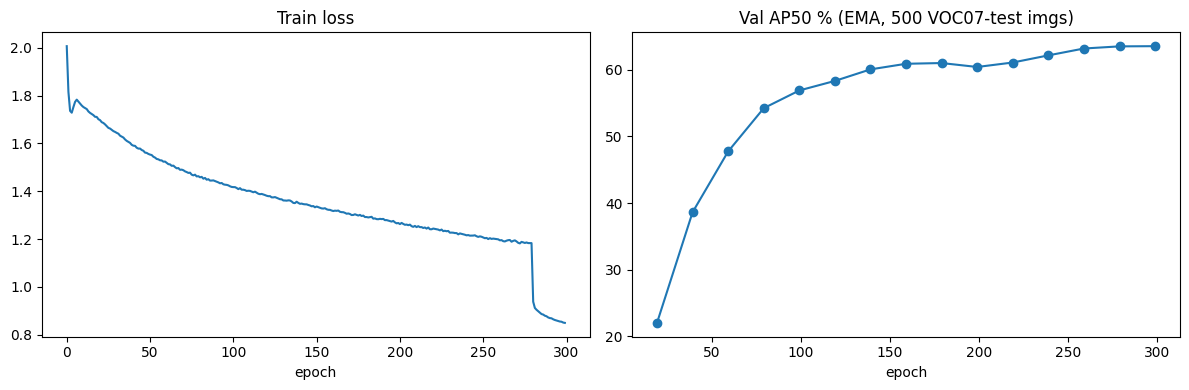

In [18]:
# Training progress report + curves
try:
    import torch
    import pandas as pd
    import matplotlib.pyplot as plt

    last_ckpt = RUN_DIR / "last.pt"
    if last_ckpt.is_file():
        done_ep = int(torch.load(str(last_ckpt), map_location="cpu", weights_only=False)["epoch"]) + 1
        print(f"Completed epochs: {done_ep}/{EPOCHS}" + ("" if done_ep >= EPOCHS else "  -> resume in the next session"))
    log_path = RUN_DIR / "train_log.csv"
    if log_path.is_file():
        df = pd.read_csv(log_path)
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(df["epoch"], df["loss"])
        axes[0].set_title("Train loss")
        axes[0].set_xlabel("epoch")
        v = df.dropna(subset=["val_ap50"])
        if len(v):
            axes[1].plot(v["epoch"], v["val_ap50"] * 100, marker="o")
        axes[1].set_title("Val AP50 % (EMA, 500 VOC07-test imgs)")
        axes[1].set_xlabel("epoch")
        plt.tight_layout()
        plt.show()
except Exception as e:
    print("Report skipped:", e)

## 6) دمج QARepVGG وتصدير ONNX وتكميم INT8 (QDQ)
يتحقق السكربت من تطابق الشبكة قبل/بعد الدمج، ثم يصدّر `opset 17` وينفّذ PTQ بـ 300 صورة معايرة.
إن زاد فقدان الدقة عن ~2% جرّب إضافة `--u8u8` أو أعد المعايرة بدون `--reduce-range`.

In [19]:
OUT_DIR = WORK / "outputs"
if RUN_EXPORT_QUANTIZE:
    final_ema = RUN_DIR / f"ema_ep{EPOCHS - 1:03d}.pt"
    weights = final_ema if final_ema.is_file() else RUN_DIR / "last.pt"
    if not final_ema.is_file():
        print("WARNING: training is not complete; exporting from last.pt (EMA weights of the latest epoch).")
    sh(f"python -u -m swiftdet.export_quantize --weights '{weights}' --calib-dir '{CALIB_DIR}' "
       f"--out-dir '{OUT_DIR}' --reduce-range")

$ python -u -m swiftdet.export_quantize --weights '/kaggle/working/runs/swiftdet_voc480/ema_ep299.pt' --calib-dir '/kaggle/working/data/voc_download/VOCdevkit/VOC2007/JPEGImages' --out-dir '/kaggle/working/outputs' --reduce-range
[Fusion Verification] max_abs_diff = 3.457e-06
[Deploy Model] Total Params = 1,725,980 (1.7260 M)
/kaggle/working/swiftdet/export_quantize.py:53: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, path, dynamo=False, **kwargs)
[Calibration] 300 images from /kaggle/working/data/voc_download/VOCdevkit/VOC2007/JPEGImages
FP32 ONNX: 6.95 MB
INT8 ONNX: 2.02 MB


## 7) تقييم الدقة (VOC2007 test) لنسختي FP32 وINT8

In [20]:
if RUN_EVAL_ONNX:
    for name in ("swiftdet_voc480_fp32.onnx", "swiftdet_voc480_int8_qdq.onnx"):
        p = OUT_DIR / name
        if p.is_file():
            sh(f"python -u -m swiftdet.eval_voc --onnx '{p}' --voc-root '{DATA_ROOT}'")
        else:
            print("missing:", p)

$ python -u -m swiftdet.eval_voc --onnx '/kaggle/working/outputs/swiftdet_voc480_fp32.onnx' --voc-root '/kaggle/input:/kaggle/working/data/voc_download'
  evaluated 500/4952 images
  evaluated 1000/4952 images
  evaluated 1500/4952 images
  evaluated 2000/4952 images
  evaluated 2500/4952 images
  evaluated 3000/4952 images
  evaluated 3500/4952 images
  evaluated 4000/4952 images
  evaluated 4500/4952 images
ONNX: /kaggle/working/outputs/swiftdet_voc480_fp32.onnx | AP50 = 64.62% | mAP50-95 = 38.86%
$ python -u -m swiftdet.eval_voc --onnx '/kaggle/working/outputs/swiftdet_voc480_int8_qdq.onnx' --voc-root '/kaggle/input:/kaggle/working/data/voc_download'
  evaluated 500/4952 images
  evaluated 1000/4952 images
  evaluated 1500/4952 images
  evaluated 2000/4952 images
  evaluated 2500/4952 images
  evaluated 3000/4952 images
  evaluated 3500/4952 images
  evaluated 4000/4952 images
  evaluated 4500/4952 images
ONNX: /kaggle/working/outputs/swiftdet_voc480_int8_qdq.onnx | AP50 = 64.23% | 

## 8) قياس الكمون (على معالج Kaggle)
الأرقام هنا **ليست** لمعالج i5-3320M. شغّل `swiftdet/benchmark_cpu.py` على الجهاز الهدف للحصول على القياس الحقيقي.

In [21]:
if RUN_CPU_BENCHMARK:
    for name in ("swiftdet_voc480_fp32.onnx", "swiftdet_voc480_int8_qdq.onnx"):
        p = OUT_DIR / name
        if p.is_file():
            sh(f"python -u -m swiftdet.benchmark_cpu --onnx '{p}' --threads 4 --iters 100")

$ python -u -m swiftdet.benchmark_cpu --onnx '/kaggle/working/outputs/swiftdet_voc480_fp32.onnx' --threads 4 --iters 100
Model: /kaggle/working/outputs/swiftdet_voc480_fp32.onnx (6.95 MB)
  Host: x86_64 | Threads=4 | Warmup=30 | Iters=100
  Model-Only Latency -> p50: 13.92 ms | p95: 15.26 ms (71.8 FPS)
  End-to-End (+NMS)  -> p50: 19.74 ms | p95: 21.54 ms (50.7 FPS)
  Peak RSS Memory    -> 583.4 MB
$ python -u -m swiftdet.benchmark_cpu --onnx '/kaggle/working/outputs/swiftdet_voc480_int8_qdq.onnx' --threads 4 --iters 100
Model: /kaggle/working/outputs/swiftdet_voc480_int8_qdq.onnx (2.02 MB)
  Host: x86_64 | Threads=4 | Warmup=30 | Iters=100
  Model-Only Latency -> p50: 26.90 ms | p95: 28.70 ms (37.2 FPS)
  End-to-End (+NMS)  -> p50: 32.82 ms | p95: 35.02 ms (30.5 FPS)
  Peak RSS Memory    -> 579.2 MB


## 9) تجميع المخرجات وتنظيف المساحة

In [22]:
if OUT_DIR.is_dir() and any(OUT_DIR.iterdir()):
    archive = shutil.make_archive(str(WORK / "swiftdet_results"), "zip", root_dir=str(OUT_DIR))
    print("Results archive:", archive)

if CLEAN_DOWNLOADED_VOC_AT_END and downloaded_any and DL_DIR.is_dir():
    shutil.rmtree(DL_DIR, ignore_errors=True)
    print("Removed downloaded VOC copy to keep the committed output small.")

for p in sorted(WORK.glob("**/*")):
    if p.is_file() and p.suffix in {".pt", ".onnx", ".zip", ".csv"}:
        print(f"{p.relative_to(WORK)}  {p.stat().st_size / 1e6:.2f} MB")

Results archive: /kaggle/working/swiftdet_results.zip
Removed downloaded VOC copy to keep the committed output small.
outputs/swiftdet_voc480_fp32.onnx  6.95 MB
outputs/swiftdet_voc480_int8_qdq.onnx  2.02 MB
outputs/swiftdet_voc480_prep.onnx  6.96 MB
runs/swiftdet_voc480/ema_ep024.pt  7.28 MB
runs/swiftdet_voc480/ema_ep049.pt  7.28 MB
runs/swiftdet_voc480/ema_ep074.pt  7.28 MB
runs/swiftdet_voc480/ema_ep099.pt  7.28 MB
runs/swiftdet_voc480/ema_ep124.pt  7.28 MB
runs/swiftdet_voc480/ema_ep149.pt  7.28 MB
runs/swiftdet_voc480/ema_ep174.pt  7.28 MB
runs/swiftdet_voc480/ema_ep199.pt  7.28 MB
runs/swiftdet_voc480/ema_ep224.pt  7.28 MB
runs/swiftdet_voc480/ema_ep249.pt  7.28 MB
runs/swiftdet_voc480/ema_ep274.pt  7.28 MB
runs/swiftdet_voc480/ema_ep299.pt  7.28 MB
runs/swiftdet_voc480/last.pt  21.71 MB
runs/swiftdet_voc480/train_log.csv  0.02 MB
swiftdet_results.zip  14.33 MB
